# Spot or fixed price electricity?

This project is a decision support system that tells an electricity company whether a household would be better off with a spot price or a fixed price contract, based only on how the household uses electricity.

Data: about 1000 London households from 2013, priced with Finnish spot prices from 2024. Models: decision tree and KNN.

Data used for this project:

London household data: "https://data.london.gov.uk/dataset/smartmeter-energy-consumption-data-in-london-households-vqm0d"

Historical finnish spot prices API:"https://dashboard.elering.ee/api/nps/price"


Initial data was quite substantial, and so I made the choice of using a smaller part of it, to save on hardware-resources, since the Colab-runtime does not posess too much memory.



The first run takes a little while and saves the processed data to Google Drive. After that it works much faster.

## Setup

If the processed data is already on Drive, SKIP is True and the download is then skipped.

In [28]:
#imports in the beginning
import os, glob, requests
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from google.colab import drive
from sklearn.model_selection import train_test_split, cross_val_score, GridSearchCV
from sklearn.preprocessing import MinMaxScaler
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, accuracy_score


pd.set_option("display.float_format", "{:.3f}".format)


drive.mount("/content/drive")
D = "/content/drive/MyDrive/"
RAW = D + "hourly_raw.parquet"
PRICES = D + "fi_prices_2024.parquet"



SKIP = os.path.exists(RAW)
print("Skipping etl", SKIP)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Skipping etl True


## Data

Smart meter data from the Low Carbon London project. 168 csv files, 1 million rows each, one row per household per half hour.

In [29]:
if not SKIP:
    !wget -q -O london168.zip "https://data.london.gov.uk/download/vqm0d/04feba67-f1a3-4563-98d0-f3071e3d56d1/Partitioned%20LCL%20Data.zip"
    !unzip -o -q london168.zip -d london_data
    files = sorted(glob.glob("london_data/**/*.csv", recursive=True))
    print(len(files), "files")
    print(pd.read_csv(files[0], nrows=5))

40 evenly spaced files I have deemed are enough ( still over 1000 households before further cleaning, but will remain close to 1000). Loading all 40 at once would need about 10 GB of memory, so they are read one by one. From each file only the Std (flat rate) households are kept, since the ToU households had a special tariff in the trial. Half hours are summed into hours, and hours with a missing half hour are dropped.

First run gave: 237 ToU households and 28 493 incomplete hours dropped, 1122 households kept.

In [30]:
if not SKIP:
    idx = np.linspace(0, len(files) - 1, 40, dtype=int)
    files_picked = [files[i] for i in idx]

    parts = []
    for i, f in enumerate(files_picked, 1):
        df = pd.read_csv(f, usecols=[0, 1, 2, 3])
        df.columns = ["household_id", "tariff_type", "timestamp", "kwh"]
        df = df[df["tariff_type"] == "Std"]


        #kwh is read as text and has some "Null" values
        df["kwh"] = pd.to_numeric(df["kwh"], errors="coerce")
        df["timestamp"] = pd.to_datetime(df["timestamp"], errors="coerce")
        df = df.dropna(subset=["kwh", "timestamp"])

        df["hour"] = df["timestamp"].dt.floor("h")
        part = df.groupby(["household_id", "hour"], as_index=False).agg(kwh=("kwh", "sum"), n=("kwh", "count"))
        parts.append(part)
        print(i, end=" ")


    #a household can be split between two files
    hourly = pd.concat(parts)
    hourly = hourly.groupby(["household_id", "hour"], as_index=False)[["kwh", "n"]].sum()
    hourly = hourly[hourly["n"] == 2].drop(columns="n")
    hourly.to_parquet(RAW)
else:
    hourly = pd.read_parquet(RAW)

print(hourly["household_id"].nunique(), "households,", len(hourly), "rows")

1122 households, 16463505 rows


## Cleaning

No missing values or negative readings. A typical hour is about 0.25 kWh.

In [31]:
print("From", hourly["hour"].min(), "to", hourly["hour"].max())
print(hourly["kwh"].describe())
print(hourly.isna().sum().sum(), "missing values")

From 2011-11-23 09:00:00 to 2014-02-28 00:00:00
count   16463505.000
mean           0.428
std            0.569
min            0.000
25%            0.124
50%            0.247
75%            0.494
max           14.770
Name: kwh, dtype: float64
0 missing values


household with the id of "MAC004067" has only zeros, could be for example a dead meter, so it's dropped. Others with lots of zeros are kept though, since an often empty home is still a customer.

In [32]:
hourly["zero"] = hourly["kwh"] == 0
print(round(hourly["zero"].mean() * 100, 2), "% of all hours are zero")

zero_share = hourly.groupby("household_id")["zero"].mean()
print(zero_share.sort_values(ascending=False).head(10))

bad = zero_share[zero_share > 0.9].index
hourly = hourly[~hourly["household_id"].isin(bad)].drop(columns="zero")
print("Dropped:", list(bad))

0.79 % of all hours are zero
household_id
MAC004067   1.000
MAC002050   0.656
MAC002564   0.655
MAC005033   0.617
MAC000004   0.581
MAC001082   0.403
MAC000912   0.403
MAC000134   0.387
MAC000636   0.384
MAC002224   0.269
Name: zero, dtype: float64
Dropped: ['MAC004067']


Prices change with the seasons, so a full year is needed. 2013 is the only full year where almost every household has data.

In [33]:
print(hourly.groupby(hourly["hour"].dt.year)["household_id"].nunique())

hour
2011     107
2012    1099
2013    1102
2014     998
Name: household_id, dtype: int64


Only 2013 is kept, and only households with at least 90% of the year's hours. The threshold barely changes the count.

In [34]:
hourly13 = hourly[hourly["hour"].dt.year == 2013]
hours_2013 = hourly13.groupby("household_id").size()

for share in [0.8, 0.9, 0.95]:
    print(share, "of 2013:", (hours_2013 >= share * 8760).sum(), "households")

keep = hours_2013[hours_2013 >= 0.9 * 8760].index
hourly13 = hourly13[hourly13["household_id"].isin(keep)].copy()
print(len(keep), "households kept")

0.8 of 2013: 1007 households
0.9 of 2013: 985 households
0.95 of 2013: 974 households
985 households kept


## Spot prices

Finnish day-ahead prices from the estonian Elering's free API. 2024 is used because Elering's 2013 data is missing every Friday, and because 2024 is quite recent and prices with their fluctuations, especially in January, are closer to today's reality. The data matches published figures (average 4.56 c/kWh without VAT, top hour 189.6 c/kWh on 5 January 2024).

8783 hours
count   8783.000
mean       4.558
std        7.443
min       -2.001
25%        0.500
50%        2.764
75%        6.288
max      189.600
Name: price_c_kwh, dtype: float64


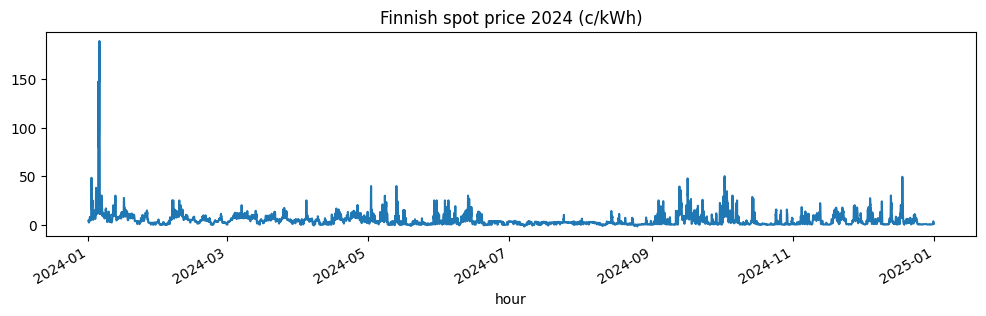

In [35]:
def get_prices(year):
    url = "https://dashboard.elering.ee/api/nps/price"
    parts = []
    for month in range(1, 13):
        #start at Finnish midnight, the months overlap a bit and duplicates are dropped below
        start = pd.Timestamp(year, month, 1) - pd.Timedelta(hours=2)
        end = start + pd.Timedelta(days=31)
        params = {"start": start.strftime("%Y-%m-%dT%H:%M:%SZ"), "end": end.strftime("%Y-%m-%dT%H:%M:%SZ")}
        r = requests.get(url, params=params)
        parts.append(pd.DataFrame(r.json()["data"]["fi"]))
    p = pd.concat(parts).drop_duplicates("timestamp")

    time = pd.to_datetime(p["timestamp"], unit="s", utc=True).dt.tz_convert("Europe/Helsinki")
    p["hour"] = time.dt.tz_localize(None).dt.floor("h")
    p = p[p["hour"].dt.year == year]
    p = p.groupby("hour", as_index=False)["price"].mean()
    p["price_c_kwh"] = p["price"] / 10 #EUR/MWh to c/kWh
    return p[["hour", "price_c_kwh"]]

if os.path.exists(PRICES):
    prices = pd.read_parquet(PRICES)
else:
    prices = get_prices(2024)
    prices.to_parquet(PRICES)

print(len(prices), "hours")
print(prices["price_c_kwh"].describe())
prices.set_index("hour")["price_c_kwh"].plot(figsize=(12, 3), title="Finnish spot price 2024 (c/kWh)")
plt.show()

## Cost on spot

2013 is moved 4018 days (574 weeks) forward so each hour lands on the same weekday in 2024. Each hour's kWh is multiplied by the spot price plus a 0.5 c/kWh margin. The missing hour on 31 March is the clock change, it gets the previous hour's price.

eff_spot_price is the household's own average price on spot.

985 household hours without a price
       annual_kwh  spot_cost_c  spot_cost_eur  eff_spot_price
count     985.000      985.000        985.000         985.000
mean     3762.108    21008.509        210.085           5.582
std      2668.951    14963.129        149.631           0.424
min        22.149      228.440          2.284           3.589
25%      2015.153    11072.436        110.724           5.349
50%      3102.026    17262.538        172.625           5.570
75%      4768.150    26859.469        268.595           5.811
max     22487.910   125288.513       1252.885          10.314


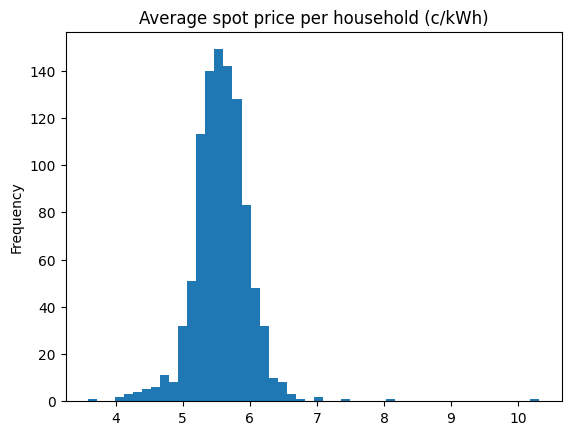

In [36]:
hourly13["price_hour"] = hourly13["hour"] + pd.Timedelta(days=4018)
hourly13 = hourly13.merge(prices.rename(columns={"hour": "price_hour"}), on="price_hour", how="left")
print(hourly13["price_c_kwh"].isna().sum(), "household hours without a price")
hourly13["price_c_kwh"] = hourly13["price_c_kwh"].ffill()

MARGIN = 0.5
hourly13["spot_cost_c"] = hourly13["kwh"] * (hourly13["price_c_kwh"] + MARGIN)

costs = hourly13.groupby("household_id")[["kwh", "spot_cost_c"]].sum().reset_index()
costs.columns = ["household_id", "annual_kwh", "spot_cost_c"]
costs["spot_cost_eur"] = costs["spot_cost_c"] / 100
costs["eff_spot_price"] = costs["spot_cost_c"] / costs["annual_kwh"]

print(costs.describe())
costs["eff_spot_price"].plot(kind="hist", bins=50, title="Average spot price per household (c/kWh)")
plt.show()

household id "MAC002564" used only 22 kWh in the whole year (the next smallest 288 kWh), basically an empty home, so it's dropped.

In [37]:
print(costs.nsmallest(5, "annual_kwh"))

costs = costs[costs["annual_kwh"] >= 100].copy()
hourly13 = hourly13[hourly13["household_id"].isin(costs["household_id"])]
print(len(costs), "households left")

    household_id  annual_kwh  spot_cost_c  spot_cost_eur  eff_spot_price
414    MAC002564      22.149      228.440          2.284          10.314
962    MAC005472     287.905     1735.616         17.356           6.028
451    MAC002744     331.482     1656.031         16.560           4.996
751    MAC004317     355.504     1871.189         18.712           5.263
896    MAC005033     384.788     2259.506         22.595           5.872
984 households left


## Fixed price and the label

With real 2024 fixed prices (about 7.3 c/kWh without VAT) spot would be cheaper for almost everyone. So the fixed price is set to the average household's spot price, and the question becomes whose usage makes spot cheaper or more expensive than average.

best_plan = spot if spot was cheaper over the year, otherwise fixed.

In [38]:
FIXED = costs["eff_spot_price"].mean()
print("Fixed price:", round(FIXED, 2), "c/kWh")


costs["fixed_cost_eur"] = costs["annual_kwh"] * FIXED / 100
costs["saving_spot_eur"] = costs["fixed_cost_eur"] - costs["spot_cost_eur"] #positive means that spot was cheaper
costs["best_plan"] = np.where(costs["saving_spot_eur"] > 0, "spot", "fixed")

print(costs["best_plan"].value_counts())
print(costs["saving_spot_eur"].describe())

for f in [FIXED - 0.5, FIXED - 0.25, FIXED, FIXED + 0.25, FIXED + 0.5]:
    print("fixed", round(f, 2), "c/kWh, spot cheaper for", round((costs["eff_spot_price"] < f).mean() * 100), "% of households")

Fixed price: 5.58 c/kWh
best_plan
spot     497
fixed    487
Name: count, dtype: int64
count   984.000
mean     -0.281
std      19.978
min     -77.526
25%      -7.096
50%       0.114
75%       5.550
max     230.993
Name: saving_spot_eur, dtype: float64
fixed 5.08 c/kWh, spot cheaper for 8 % of households
fixed 5.33 c/kWh, spot cheaper for 23 % of households
fixed 5.58 c/kWh, spot cheaper for 51 % of households
fixed 5.83 c/kWh, spot cheaper for 77 % of households
fixed 6.08 c/kWh, spot cheaper for 92 % of households


## Features

One row per household describing its habits: daily use and how much it varies, share of use at night (0-6), morning (6-9), day (9-17), evening (17-22), winter and summer, weekend vs weekday use, and how varying / spiky the usage is. Price columns are not used as features since the label comes from them.

In [39]:
def make_features(df):
    hour = df["hour"].dt.hour
    month = df["hour"].dt.month
    weekend = df["hour"].dt.dayofweek >= 5
    total = df.groupby("household_id")["kwh"].sum()

    daily = df.groupby(["household_id", df["hour"].dt.date])["kwh"].sum().reset_index()
    out = daily.groupby("household_id")["kwh"].agg(["mean", "std"])
    out.columns = ["mean_daily_kwh", "std_daily_kwh"]
    out["cv_daily"] = out["std_daily_kwh"] / out["mean_daily_kwh"]



    out["night_share"] = df[hour < 6].groupby("household_id")["kwh"].sum() / total
    out["morning_share"] = df[(hour >= 6) & (hour < 9)].groupby("household_id")["kwh"].sum() / total
    out["day_share"] = df[(hour >= 9) & (hour < 17)].groupby("household_id")["kwh"].sum() / total
    out["evening_share"] = df[(hour >= 17) & (hour < 22)].groupby("household_id")["kwh"].sum() / total
    out["winter_share"] = df[month.isin([12, 1, 2])].groupby("household_id")["kwh"].sum() / total
    out["summer_share"] = df[month.isin([6, 7, 8])].groupby("household_id")["kwh"].sum() / total


    weekend_avg = df[weekend].groupby("household_id")["kwh"].mean()
    weekday_avg = df[~weekend].groupby("household_id")["kwh"].mean()
    out["weekend_ratio"] = weekend_avg / weekday_avg
    out["peak_to_mean"] = df.groupby("household_id")["kwh"].max() / df.groupby("household_id")["kwh"].mean()
    return out

features = make_features(hourly13).reset_index()
features = features.merge(costs[["household_id", "annual_kwh", "saving_spot_eur", "best_plan"]], on="household_id")

print(features.shape)
print(features.isna().sum().sum(), "missing values")
print(features.describe().T)

(984, 15)
0 missing values
                  count     mean      std     min      25%      50%      75%  \
mean_daily_kwh  984.000   10.330    7.310   0.789    5.527    8.535   13.142   
std_daily_kwh   984.000    3.718    3.593   0.227    1.615    2.686    4.400   
cv_daily        984.000    0.356    0.191   0.066    0.237    0.317    0.424   
night_share     984.000    0.153    0.083   0.035    0.111    0.138    0.172   
morning_share   984.000    0.112    0.038   0.017    0.090    0.108    0.128   
day_share       984.000    0.343    0.067   0.045    0.306    0.342    0.382   
evening_share   984.000    0.303    0.062   0.045    0.267    0.303    0.340   
winter_share    984.000    0.285    0.046   0.074    0.259    0.280    0.301   
summer_share    984.000    0.214    0.044   0.001    0.198    0.219    0.240   
weekend_ratio   984.000    1.064    0.145   0.290    0.992    1.045    1.120   
peak_to_mean    984.000    9.728    5.238   2.779    6.667    8.598   11.452   
annual_kwh   

## EDA

The classes are balanced, so guessing gives about 50%. In the box plots, features where the spot and fixed boxes differ are the useful ones.

best_plan
spot     497
fixed    487
Name: count, dtype: int64


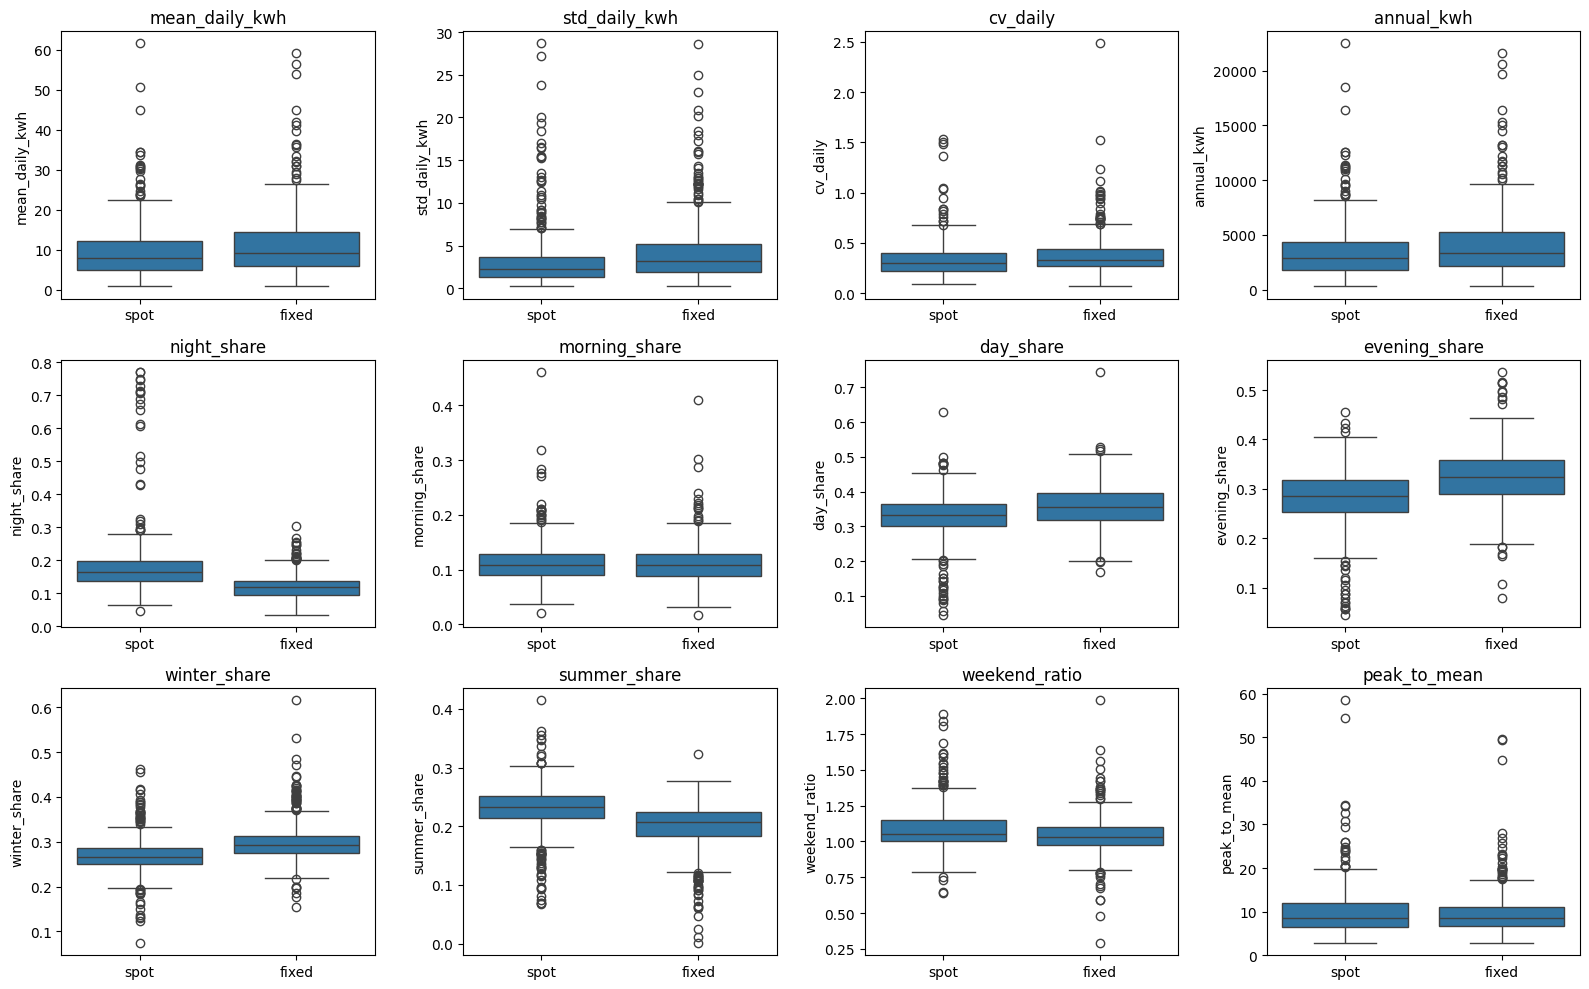

In [40]:
FEATS = ["mean_daily_kwh", "std_daily_kwh", "cv_daily", "annual_kwh",
         "night_share", "morning_share", "day_share", "evening_share",
         "winter_share", "summer_share", "weekend_ratio", "peak_to_mean"]

print(features["best_plan"].value_counts())

fig, axes = plt.subplots(3, 4, figsize=(16, 10))
for ax, col in zip(axes.flat, FEATS):
    sns.boxplot(data=features, x="best_plan", y=col, ax=ax)
    ax.set_title(col)
    ax.set_xlabel("")
plt.tight_layout()
plt.show()

mean_daily_kwh and annual_kwh correlate 1.00 (annual = daily × 365), so annual_kwh is dropped. No other pair is above 0.9.

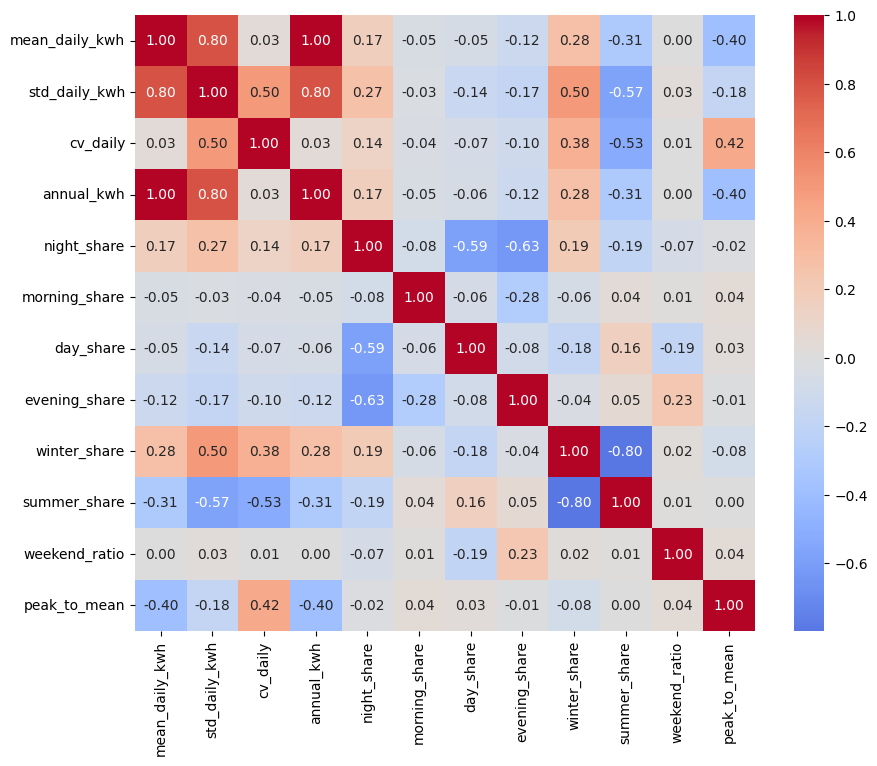

In [41]:
plt.figure(figsize=(10, 8))
sns.heatmap(features[FEATS].corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.show()

In [42]:
X = features[FEATS]
scaled = (X - X.min()) / (X.max() - X.min())
print(scaled.var().sort_values())

cv_daily         0.006
winter_share     0.007
weekend_ratio    0.007
morning_share    0.007
peak_to_mean     0.009
day_share        0.009
summer_share     0.011
night_share      0.013
annual_kwh       0.014
mean_daily_kwh   0.014
std_daily_kwh    0.016
evening_share    0.016
dtype: float64


## Preprocessing

Using a typical 80/20 train/test split. One-hot encoding of usage band for  low/medium/high, also used for fairness later. Min-max normalization fitted on the training data only, so nothing leaks from the test set.

In [43]:
FINAL = [c for c in FEATS if c != "annual_kwh"]
y_label = (features["best_plan"] == "spot").astype(int) #1 = spot, 0 = fixed

X_train, X_test, y_train, y_test = train_test_split(
    features[FINAL], y_label, test_size=0.2, random_state=42, stratify=y_label)

low_cut, high_cut = X_train["mean_daily_kwh"].quantile([1/3, 2/3])
def band(x):
    return pd.cut(x, [0, low_cut, high_cut, 1000], labels=["low", "medium", "high"])

band_train = band(X_train["mean_daily_kwh"])
band_test = band(X_test["mean_daily_kwh"])
X_train = X_train.join(pd.get_dummies(band_train, prefix="usage", dtype=int))
X_test = X_test.join(pd.get_dummies(band_test, prefix="usage", dtype=int))



scaler = MinMaxScaler()
X_train_s = pd.DataFrame(scaler.fit_transform(X_train), columns=X_train.columns, index=X_train.index)
X_test_s = pd.DataFrame(scaler.transform(X_test), columns=X_test.columns, index=X_test.index)


print(X_train_s.shape, X_test_s.shape)

(787, 14) (197, 14)


## Decision tree

Gini vs entropy (information gain) at depths 1-15, with 5-fold cross-validation on the training data. Training accuracy goes to 1.0 while cross-validation peaks around depth 4 and then drops, which is overfitting.

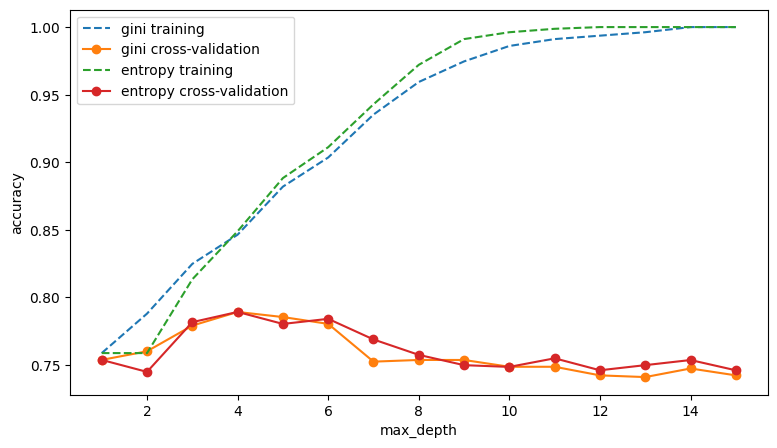

In [44]:
depths = range(1, 16)
plt.figure(figsize=(9, 5))
for crit in ["gini", "entropy"]:
    train_acc = []
    cv_acc = []
    for depth in depths:
        tree = DecisionTreeClassifier(criterion=crit, max_depth=depth, random_state=42).fit(X_train_s, y_train)
        train_acc.append(tree.score(X_train_s, y_train))
        cv_acc.append(cross_val_score(tree, X_train_s, y_train, cv=5).mean())
    plt.plot(depths, train_acc, "--", label=crit + " training")
    plt.plot(depths, cv_acc, "-o", label=crit + " cross-validation")



plt.xlabel("max_depth")
plt.ylabel("accuracy")
plt.legend()
plt.show()

Grid search over criterion, max_depth and min_samples_split (the stopping criteria).

In [45]:
params = {"criterion": ["gini", "entropy"],
          "max_depth": [2, 3, 4, 5, 6, 8, 10],
          "min_samples_split": [2, 10, 20, 50]}

grid = GridSearchCV(DecisionTreeClassifier(random_state=42), params, cv=5)
grid.fit(X_train_s, y_train)
print("Best settings:", grid.best_params_)
print("Cross-validation accuracy:", round(grid.best_score_, 3))

Best settings: {'criterion': 'entropy', 'max_depth': 6, 'min_samples_split': 50}
Cross-validation accuracy: 0.802


Test accuracy and feature importances. The tree relies mostly on night_share, so when electricity is used matters more than how much. Thresholds in the plot are on the 0-1 scale.

Test accuracy: 0.772
night_share      0.415
summer_share     0.223
winter_share     0.142
weekend_ratio    0.116
day_share        0.040
evening_share    0.030
peak_to_mean     0.024
mean_daily_kwh   0.011
dtype: float64


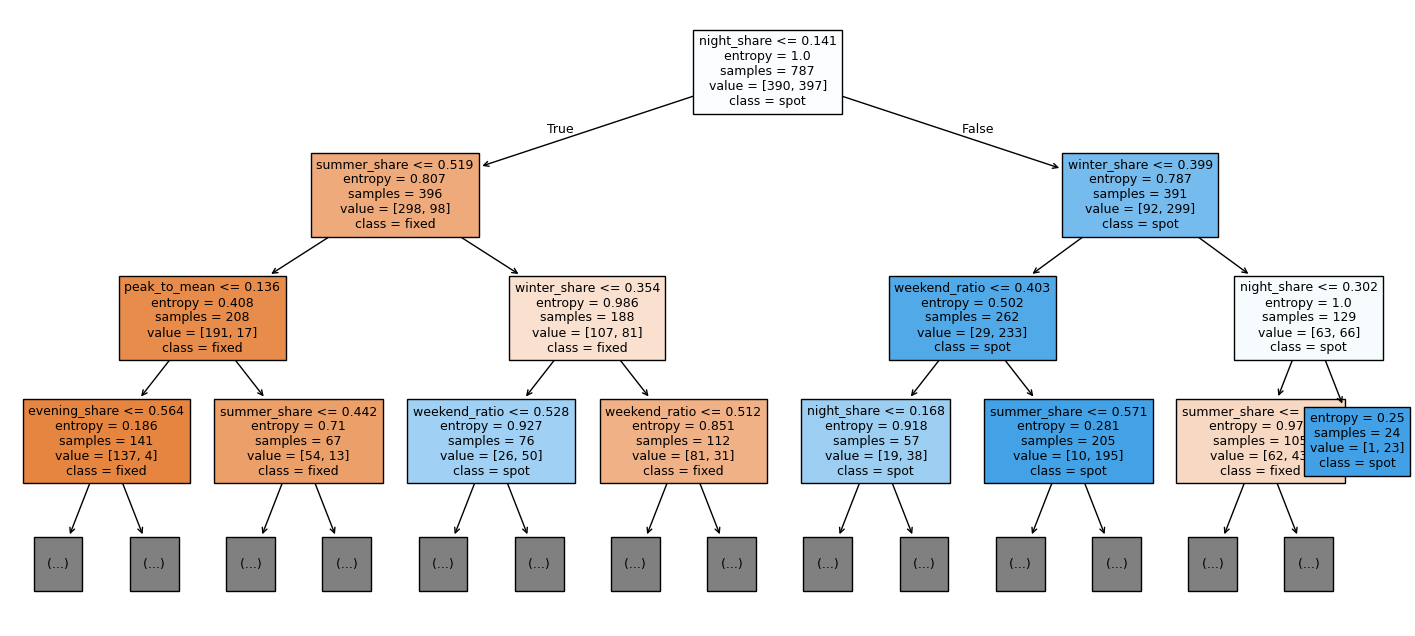

In [46]:
best_tree = grid.best_estimator_
print("Test accuracy:", round(best_tree.score(X_test_s, y_test), 3))

imp = pd.Series(best_tree.feature_importances_, index=X_train_s.columns).sort_values(ascending=False)
print(imp[imp > 0])

plt.figure(figsize=(18, 8))
plot_tree(best_tree, feature_names=X_train_s.columns, class_names=["fixed", "spot"],
          filled=True, max_depth=3, fontsize=9)
plt.show()

So, most mistakes are households where the plans cost almost the same. Accuracy goes up when only bigger differences are counted.

In [47]:
pred = best_tree.predict(X_test_s)
diff = features.loc[X_test_s.index, "saving_spot_eur"].abs()

for limit in [0, 5, 10, 20]:
    m = diff > limit
    print("difference over", limit, "€:", m.sum(), "households, accuracy", round((pred[m] == y_test[m]).mean(), 2))

difference over 0 €: 197 households, accuracy 0.77
difference over 5 €: 111 households, accuracy 0.8
difference over 10 €: 61 households, accuracy 0.89
difference over 20 €: 21 households, accuracy 0.95


## KNN

Odd k from 1 to 39 tested with cross-validation, the best k is used.

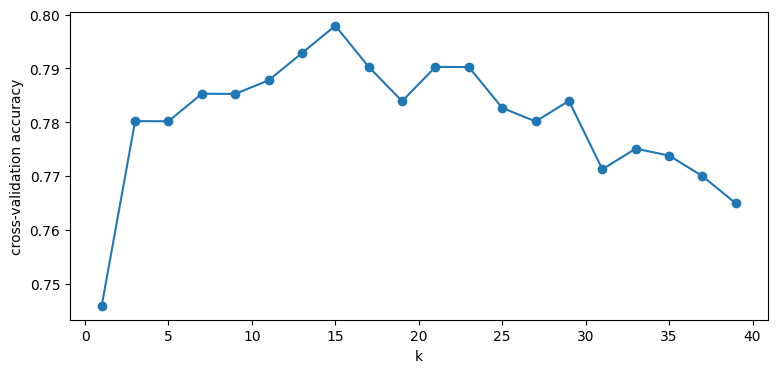

Best k: 15
Test accuracy: 0.812


In [48]:
ks = list(range(1, 41, 2))
cv_acc = []
for k in ks:
    cv_acc.append(cross_val_score(KNeighborsClassifier(n_neighbors=k), X_train_s, y_train, cv=5).mean())

plt.figure(figsize=(9, 4))
plt.plot(ks, cv_acc, "-o")
plt.xlabel("k")
plt.ylabel("cross-validation accuracy")
plt.show()

best_k = ks[cv_acc.index(max(cv_acc))]
knn = KNeighborsClassifier(n_neighbors=best_k).fit(X_train_s, y_train)
print("Best k:", best_k)
print("Test accuracy:", round(knn.score(X_test_s, y_test), 3))

## Evaluation

Both models vs a simple rule (spot if night_share is above the median). Rows are the plan that was really cheaper, columns the recommendation. Recommending spot wrongly is the worse mistake, since it also exposes the customer to price spikes.

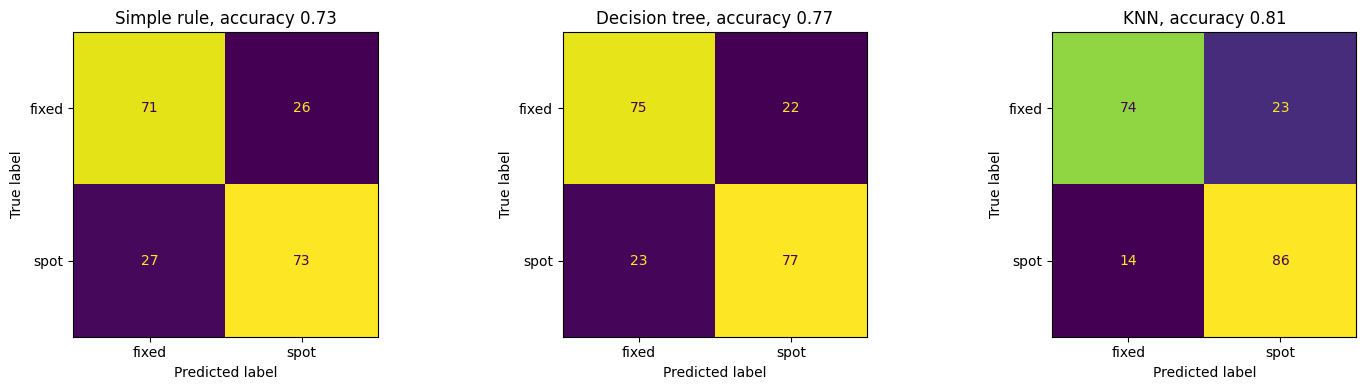

In [49]:
rule_pred = (X_test_s["night_share"] > X_train_s["night_share"].median()).astype(int)

models = {"Simple rule": rule_pred,
          "Decision tree": best_tree.predict(X_test_s),
          "KNN": knn.predict(X_test_s)}

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, name in zip(axes, models):
    pred = models[name]
    ConfusionMatrixDisplay(confusion_matrix(y_test, pred), display_labels=["fixed", "spot"]).plot(ax=ax, colorbar=False)
    ax.set_title(name + ", accuracy " + str(round(accuracy_score(y_test, pred), 2)))
plt.tight_layout()
plt.show()

## Fairness

Checked across usage bands since there's no housing type. Similar false spot and false fixed rates across groups = error rate balance, similar precision = predictive parity. Groups are small (about 65), so only big gaps count. Low usage households come out worst for both models.

In [50]:
for name in ["Decision tree", "KNN"]:
    pred = pd.Series(models[name], index=y_test.index)
    for g in ["low", "medium", "high"]:
        tn, fp, fn, tp = confusion_matrix(y_test[band_test == g], pred[band_test == g], labels=[0, 1]).ravel()
        print(name, g,
              "| n", tn + fp + fn + tp,
              "| accuracy", round((tp + tn) / (tn + fp + fn + tp), 2),
              "| false spot", round(fp / (fp + tn), 2),
              "| false fixed", round(fn / (fn + tp), 2),
              "| precision", round(tp / (tp + fp), 2))

Decision tree low | n 65 | accuracy 0.71 | false spot 0.22 | false fixed 0.34 | precision 0.81
Decision tree medium | n 72 | accuracy 0.79 | false spot 0.24 | false fixed 0.17 | precision 0.76
Decision tree high | n 60 | accuracy 0.82 | false spot 0.21 | false fixed 0.15 | precision 0.77
KNN low | n 65 | accuracy 0.78 | false spot 0.41 | false fixed 0.08 | precision 0.76
KNN medium | n 72 | accuracy 0.81 | false spot 0.24 | false fixed 0.14 | precision 0.77
KNN high | n 60 | accuracy 0.85 | false spot 0.09 | false fixed 0.22 | precision 0.88


## Cold start

New customers only have a few weeks of data. The models get only the first 1-52 weeks of 2013 but still predict the full year's cheaper plan. winter_share and summer_share are left out since a few weeks can't show seasons.

In [51]:
train_ids = features.loc[X_train.index, "household_id"]
test_ids = features.loc[X_test.index, "household_id"]
best = grid.best_params_

for weeks in [1, 2, 4, 8, 13, 26, 52]:

    part = hourly13[hourly13["hour"] < pd.Timestamp("2013-01-01") + pd.Timedelta(weeks=weeks)]

    F = make_features(part).drop(columns=["winter_share", "summer_share"])
    F = F.replace([np.inf, -np.inf], 0).fillna(0)

    F_train = F.reindex(train_ids).fillna(0)
    F_test = F.reindex(test_ids).fillna(0)
    sc = MinMaxScaler().fit(F_train)
    F_train = sc.transform(F_train)

    F_test = sc.transform(F_test)

    tree = DecisionTreeClassifier(criterion=best["criterion"], max_depth=best["max_depth"],
                                  min_samples_split=best["min_samples_split"], random_state=42)


    tree.fit(F_train, y_train)
    knn_cs = KNeighborsClassifier(n_neighbors=best_k).fit(F_train, y_train)
    print(weeks, "weeks: tree", round(tree.score(F_test, y_test), 3), "knn", round(knn_cs.score(F_test, y_test), 3))

1 weeks: tree 0.716 knn 0.695
2 weeks: tree 0.741 knn 0.721
4 weeks: tree 0.701 knn 0.731
8 weeks: tree 0.716 knn 0.716
13 weeks: tree 0.746 knn 0.726
26 weeks: tree 0.716 knn 0.736
52 weeks: tree 0.766 knn 0.751


## Popularity bias

How often spot is recommended vs how often it really was cheaper.

In [52]:
print("Spot really cheaper:", round(y_test.mean() * 100), "%")
for name in models:
    print(name, "recommends spot to", round(np.mean(models[name]) * 100), "%")

Spot really cheaper: 51 %
Simple rule recommends spot to 50 %
Decision tree recommends spot to 50 %
KNN recommends spot to 55 %


## Conclusion

So the system recommends spot or fixed price electricity based only on a household's usage habits. 984 London households of 2013 data, priced with Finnish 2024 spot prices.

### Findings
Spot was cheaper for 497 households and fixed for 487. For most the difference is small, the median is about 0.11 € a year, this means the choice only really matters for a small amount of households.



The tree was right for 77% of the test households and KNN for 81%, vs 73% for the simple night_share rule and 50% for guessing. and most mistakes were close calls: with a difference over 10 € the tree is right 89% of the time.


When electricity is used matters most, mainly night use, then summer and winter shares and weekend use.

KNN was a slightly more accurate, but the tree can explain its recommendations, and it probably matters for a company that might have to justify the advice its giving out.

Low usage households got the worst results from both models (tree accuracy 71% vs 82% for high users). Expected. One week of data already gives about 70% accuracy. No real popularity bias: spot was cheaper for 51%, the tree recommended it to 50% and KNN to 55%.

### Some imitations

So obviously I used London households, not Finnish, Finnish homes with electric heating would probably look different. And the fixed price is the average spot cost, not a real offer. One price year only. Fairness groups are usage levels, not housing types.

### Comparing with the original project abstract

What remanied the same was a decision support system for a utility, EDA and variance analysis, min-max and one-hot, decision tree (Gini, entropy, max_depth, min_samples_split), KNN, confusion matrices, predictive parity, error rate balance, cold start and popularity bias.

What changed on the other hand was that the target is the cheaper plan instead of abnormal consumption, since there were no anomaly labels. Anomaly detection became part of cleaning instead, it made sense,  (the meter showing zero and the empty home). Fairness groups are usage levels instead of housing types. The recommender is also simpler: KNN as "households like you" and the tree as rules. And the setting is Finnish, with spot vs fixed contracts.